# GBE happiness model

Implement the happiness model described in Rutledge et al. (2014), using
development participants.

First check the equations and fitting conventions, then work through one
play before fitting more. Compare versions 1–2 and 3–5 separately.

This is an implementation check using the current release, not an exact
reproduction of the original sample.

## 1. Load the data and apply development split

Same file and participant split as notebook 3+4. 

In [2]:
from pathlib import Path
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.io import loadmat

PROJECT_DIR = Path.cwd().parents[1]
DATA_PATH = PROJECT_DIR / "data" / "raw" / "gbe" / "Rutledge_GBE_risk_data_TOD.mat"

print("Data file found:", DATA_PATH.is_file())

Data file found: True


In [3]:
mat = loadmat(DATA_PATH, simplify_cells=True)
participants = mat["subjData"]

print("People:", len(participants))

People: 47067


In [4]:
def get_plays(participant):
    # same container handling as notebook 2
    if participant["nPlays"] == 1:
        return [participant["data"]]
    return list(participant["data"])

In [5]:
import hashlib

SPLIT_PATH = Path.cwd().parent / "splits" / "gbe_split_2026-10-07.csv"
EXPECTED_SPLIT_SHA256 = "861de3c444f506c76cbac3208840fd62d57a71b6aad63fceb83a802d8da139e9"

assert hashlib.sha256(SPLIT_PATH.read_bytes()).hexdigest() == EXPECTED_SPLIT_SHA256
split = pd.read_csv(SPLIT_PATH)

assert list(split.columns) == ["id", "set"]
assert pd.api.types.is_integer_dtype(split["id"])
assert split["id"].is_unique
assert set(split["set"]) == {"development", "holdout"}

# make sure no IDs are missing or invented relative to the loaded release
loaded_ids = [int(person["id"]) for person in participants]
assert len(loaded_ids) == len(set(loaded_ids))
assert set(split["id"]) == set(loaded_ids)

development_ids = set(split.loc[split["set"] == "development", "id"])
holdout_ids = set(split.loc[split["set"] == "holdout", "id"])
assert development_ids.isdisjoint(holdout_ids)
assert len(development_ids) == 10_000
assert len(holdout_ids) == 37_067

# leave participants unchanged; keep the released ordering in this subset
development_participants = [
    person for person in participants if int(person["id"]) in development_ids
]
assert len(development_participants) == 10_000

print("Split checksum and IDs verified.")
print("Development people:", len(development_participants))
print("Reserved hold-out IDs:", len(holdout_ids))

Split checksum and IDs verified.
Development people: 10000
Reserved hold-out IDs: 37067


## 2. Build the reward histories

For each post-outcome rating, calculate the weighted CR, gamble EV and
RPE histories. Allow either seven trials or the full play history.
The most recent completed trial gets weight 1.

In [6]:
def reward_terms(play):
    chose_gamble = play[:, 6] == 1
    offered_ev = (play[:, 3] + play[:, 4]) / 2

    certain_reward = np.where(chose_gamble, 0, play[:, 2])
    gamble_ev = np.where(chose_gamble, offered_ev, 0)
    rpe = np.where(chose_gamble, play[:, 7] - offered_ev, 0)

    return np.column_stack([certain_reward, gamble_ev, rpe])

In [8]:
def reward_histories(play, gamma, window=7):
    if not 0 <= gamma <= 1:
        raise ValueError("gamma must be between 0 and 1")
    if window is not None and (
        not isinstance(window, int) or window < 1
    ):
        raise ValueError("window must be a positive integer or None")

    terms = reward_terms(play)

    # omit the baseline stored in row 0
    rating_rows = np.flatnonzero(~np.isnan(play[:, 9]))[1:]
    histories = []

    for row in rating_rows:
        end = int(play[row, 0])  # number of completed trials
        start = 0 if window is None else max(0, end - window)

        events = terms[start:end]

        # oldest event gets the largest exponent; newest gets exponent 0
        lags = np.arange(len(events) - 1, -1, -1) # e.g. for 3 events [2, 1, 0]
        # raise gamma to each lag to get the weight for each event, e.g. [0.25, 0.5, 1]
        weights = gamma ** lags 

        # multiply each event by its weight and sum to get the history for this rating
        histories.append(weights @ events)

    return np.asarray(histories)

### Check decay with certain rewards

Test the decay in made-up play with only CR events

In [ ]:
test_play = np.full((8, 15), np.nan)

test_play[:, 0] = np.arange(1, 9)
test_play[:, 2] = np.arange(1, 9)  # certain rewards
test_play[:, 3:5] = 0 # not used
test_play[:, 6] = 0               # always choose certain
test_play[:, 7] = test_play[:, 2]

test_play[0, 9] = 50  # baseline, stored in row 0
test_play[7, 9] = 60  # rating after trial 8

for gamma in [0, 0.5, 1]:
    seven = reward_histories(test_play, gamma, window=7)
    full = reward_histories(test_play, gamma, window=None)

    print(f"gamma = {gamma}")
    print("  Seven trials:", seven)
    print("  Full history:", full)

gamma = 0
  Seven trials: [[8. 0. 0.]]
  Full history: [[8. 0. 0.]]
gamma = 0.5
  Seven trials: [[14.  0.  0.]]
  Full history: [[14.0078125  0.         0.       ]]
gamma = 1
  Seven trials: [[35.  0.  0.]]
  Full history: [[36.  0.  0.]]


### Check mixed choices

Test the decay in made-up play across mixed trials

In [10]:
mixed_play = np.full((3, 15), np.nan)
mixed_play[:, 0] = [1, 2, 3]

# columns: certain amount, gamble win, gamble loss
mixed_play[:, 2:5] = [
    [0, 100, 0],    # choose gamble, receive 100
    [20, 60, 0],    # choose certain, receive 20
    [0, 40, -20],   # choose gamble, receive -20
]
mixed_play[:, 6] = [1, 0, 1]
mixed_play[:, 7] = [100, 20, -20]
mixed_play[0, 9] = 50
mixed_play[2, 9] = 60

np.testing.assert_allclose(
    reward_terms(mixed_play),
    [
        [0, 50, 50],
        [20, 0, 0],
        [0, 10, -30],
    ],
)

np.testing.assert_allclose(
    reward_histories(mixed_play, gamma=0.5),
    [[10, 22.5, -17.5]],
)

print("Mixed-choice check passed.")

Mixed-choice check passed.


## 3. Choices for the first real-data fits

Start with version 1 as the closest available comparison to the earlier fixed-start smartphone task. This won't recreate the original sample.

### Which play?

Use each development participant's first available play overall, then group those plays by version. Start with the version-1 group.

An alternative would be the first available play within each version, but that could select later plays and give some people several fits. Keep `timesPlayed` alongside the selected play: first available doesn't necessarily mean first-ever attempt.

### Which ratings and scaling?

Fit the 11 post-outcome ratings. Leave baseline out of both fitting and the mean/SD used for standardisation.

Z-score within the selected play using the sample SD (`ddof=1`), then omit the intercept. The paper describes z-scoring and intercept omission for particular analyses, but doesn't specify the standardisation unit or whether baseline entered that calculation. Sample SD matches MATLAB's default z-score convention.

### Reward history and fitting

Start with the seven-trial window as mentioned in Rutledge SI, interpreted as the most recent completed trial plus six earlier trials. Repeat with full play history because the methods leave the window's application to model 1 unclear.

Keep gamma between 0 and 1 and leave the three reward weights unrestricted. For each gamma, estimate the weights by linear least squares, then search over gamma. 

### Plays that don't identify the model

Flag constant post-outcome ratings, which can't be z-scored, and rank-deficient reward histories, which can't identify all three weights. Also inspect whether gamma has a clear optimum rather than assuming every fitted value is informative.

No slider-match or RT exclusions for this implementation check.

## 4. Work through one version-1 play

### Select first available plays

In [11]:
first_play_records = []

for participant in development_participants:
    plays = get_plays(participant)

    first_play_records.append({
        "id": int(participant["id"]),
        "available_play": 1,
        "version": int(np.atleast_1d(
            participant["designVersion"]
        )[0]),
        "timesPlayed": int(np.atleast_1d(
            participant["timesPlayed"]
        )[0]),
        "play": plays[0],
    })

first_plays = pd.DataFrame(first_play_records)

print("Selected people:", len(first_plays))
print(first_plays.groupby("version").size().rename("first_available_plays"))

Selected people: 10000
version
1    3413
2      55
3     711
4    1055
5    4766
Name: first_available_plays, dtype: int64


### Prepare the version-1 ratings

In [12]:
v1_records = []

for record in first_play_records:
    if record["version"] != 1:
        continue

    play = record["play"]
    rating_rows = np.flatnonzero(~np.isnan(play[:, 9]))[1:]
    happiness = play[rating_rows, 9]

    assert len(happiness) == 11
    assert np.isfinite(happiness).all()

    rating_sd = happiness.std(ddof=1)
    constant = np.all(happiness == happiness[0])

    v1_records.append({
        **record,
        "post_happiness": happiness.copy(),
        "rating_sd": rating_sd,
        "constant_post_ratings": bool(constant),
        "z_happiness": (
            None if constant
            else (happiness - happiness.mean()) / rating_sd
        ),
    })

print("Version-1 first available plays:", len(v1_records))
print("Constant post-outcome ratings:",
      sum(record["constant_post_ratings"] for record in v1_records))
print("First available play is a later attempt:",
      sum(record["timesPlayed"] != 1 for record in v1_records))

Version-1 first available plays: 3413
Constant post-outcome ratings: 157
First available play is a later attempt: 364


Version 1 contributes 3,413 first available plays. Of these, 157 have constant post-outcome ratings and can’t be z-scored. For 364 people, the selected play is recorded as a later attempt; these stay included.

### Inspect one prepared play
Inspect one nonconstant play at fixed gamma of 0.5

In [13]:
example_record = next(
    record for record in v1_records
    if not record["constant_post_ratings"]
)

example_X = reward_histories(
    example_record["play"], gamma=0.5, window=7
)

print("Participant:", example_record["id"])
print("History matrix shape:", example_X.shape)
print("Matrix rank:", np.linalg.matrix_rank(example_X))
print("Mean z-scored happiness:", example_record["z_happiness"].mean())
print("SD:", example_record["z_happiness"].std(ddof=1))

pd.DataFrame(example_X, columns=["CR_history", "EV_history", "RPE_history"])

Participant: 1
History matrix shape: (11, 3)
Matrix rank: 3
Mean z-scored happiness: 8.074349270001139e-17
SD: 1.0


,CR_history,EV_history,RPE_history
0,22.500000,38.500000,38.500000
1,-33.437500,26.812500,37.812500
2,50.468750,-10.468750,19.406250
3,-19.609375,-2.875000,4.593750
4,20.156250,-11.882812,-43.117188
5,-25.546875,-38.375000,-42.500000
6,4.062500,-5.054688,-5.054688
7,1.015625,45.843750,-57.656250
8,15.000000,53.375000,-54.562500
9,-20.625000,19.156250,-1.656250


### Fit weights at gamma 0.5

Looks as expected, next estimate the three weights at 0.5 gamma.

In [14]:
y = example_record["z_happiness"]

# find the weights that minimise the prediction errors; no intercept
weights, _, rank, singular_values = np.linalg.lstsq(
    example_X, y, rcond=None
)

predicted = example_X @ weights # multiply each history by its weight
residuals = y - predicted
rss = np.sum(residuals ** 2)

print("Weights [CR, EV, RPE]:", weights)
print("Residual sum of squares:", rss)

pd.DataFrame({
    "observed_z_happiness": y,
    "predicted": predicted,
    "residual": residuals,
})

Weights [CR, EV, RPE]: [-0.00574341  0.0029668   0.02013437]
Residual sum of squares: 3.4243179197782294


,observed_z_happiness,predicted,residual
0,0.762261,0.760168,0.002093
1,0.610499,1.032923,-0.422425
2,0.344915,0.069812,0.275103
3,-0.451838,0.196587,-0.648425
4,-1.476234,-1.019157,-0.457077
5,-0.451838,-0.822836,0.370998
6,-0.451838,-0.140102,-0.311736
7,-1.324472,-1.030697,-0.293775
8,-0.451838,-1.026380,0.574542
9,1.445192,0.141943,1.303249


### Search gamma on a grid

Next we try gamma from 0 to 1 in steps of 0.01 to find fit among these

In [ ]:
gamma_results = []

for gamma in np.linspace(0, 1, 101):
    X = reward_histories(
        example_record["play"], gamma=gamma, window=7
    )

    weights, _, rank, _ = np.linalg.lstsq(X, y, rcond=None)
    rss = np.sum((y - X @ weights) ** 2) # calculate explicitly becasue lstsq can return empty

    gamma_results.append({
        "gamma": gamma,
        "rss": rss,
        "rank": rank,
        "w_CR": weights[0],
        "w_EV": weights[1],
        "w_RPE": weights[2],
    })

gamma_profile = pd.DataFrame(gamma_results)

print("Rank-deficient grid points:",
      (gamma_profile["rank"] < 3).sum())

print("\nBest-fitting gamma and weights:")
best_grid = gamma_profile.loc[gamma_profile["rss"].idxmin()] # return the row with the lowest RSS
best_grid

Rank-deficient grid points: 0

Best-fitting gamma and weights:


gamma    0.300000
rss      2.862353
rank     3.000000
w_CR    -0.001209
w_EV    -0.000397
w_RPE    0.021968
Name: 30, dtype: float64

The best grid point is gamma 0.30. Check the RSS curve next: a broad, shallow minimum would mean several gamma values fit similarly, even though one has the lowest RSS.

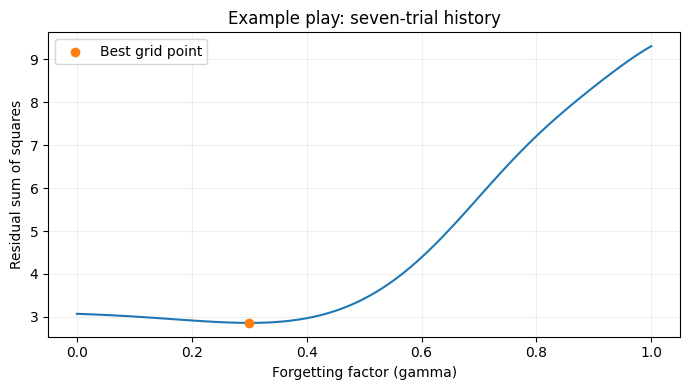

In [17]:
fig, ax = plt.subplots(figsize=(7, 4))

ax.plot(gamma_profile["gamma"], gamma_profile["rss"])
ax.scatter(
    best_grid["gamma"], best_grid["rss"],
    color="tab:orange", zorder=3, label="Best grid point",
)
ax.set_xlabel("Forgetting factor (gamma)")
ax.set_ylabel("Residual sum of squares")
ax.set_title("Example play: seven-trial history")
ax.legend()
ax.grid(alpha=0.2)

fig.tight_layout()
plt.show()

### Refine the minimum

The curve is pretty shallow around 0.3 so we can probably locate the minimum more precisely, even though this is an example play and won't precisely identify forgetting.

In [18]:
from scipy.optimize import minimize_scalar

def example_rss(gamma):
    X = reward_histories(
        example_record["play"], gamma=gamma, window=7
    )
    weights = np.linalg.lstsq(X, y, rcond=None)[0]
    return np.sum((y - X @ weights) ** 2)

refined = minimize_scalar(
    example_rss,
    bounds=(0.29, 0.31),
    method="bounded",
    options={"xatol": 1e-8},
)

assert refined.success

print(f"Refined gamma: {refined.x:.6f}")
print(f"RSS: {refined.fun:.6f}")
print(f"Improvement over grid: {best_grid['rss'] - refined.fun:.8f}")

Refined gamma: 0.300539
RSS: 2.862351
Improvement over grid: 0.00000233


Refinement barely changes the result: gamma moves from 0.30 to 0.300539, with an RSS improvement of about 0.000002. The grid was already close enough here; extra decimal places don’t mean extra certainty.

### Make the fitting function

Generalise as function that finds the gamma that best predicts one play's z-scored happiness. For each gamma, find the best CR, EV and RPE weights, then calculate and return RSS. Two steps: first search coarse grid then refine promising dips.

In [19]:
from scipy.optimize import minimize_scalar

def fit_happiness_play(play, z_happiness, window=7):
    y = np.asarray(z_happiness, dtype=float)

    def fit_at_gamma(gamma):
        X = reward_histories(play, gamma, window=window)
        assert X.shape == (len(y), 3)

        weights, _, rank, _ = np.linalg.lstsq(X, y, rcond=None)
        predicted = X @ weights

        return {
            "gamma": float(gamma),
            "rss": float(np.sum((y - predicted) ** 2)),
            "rank": int(rank),
            "weights": weights,
            "predicted": predicted,
        }

    grid = np.linspace(0, 1, 101)
    grid_fits = [fit_at_gamma(gamma) for gamma in grid]
    grid_rss = np.array([fit["rss"] for fit in grid_fits])

    # keep every grid result, including both endpoints
    candidates = grid_fits.copy()
    refinement_failures = 0

    for index in range(1, len(grid) - 1):
        left, middle, right = grid_rss[index - 1:index + 2]

        # refine local dips, but don't refine every point of a flat plateau
        if middle <= left and middle <= right and (
            middle < left or middle < right
        ):
            result = minimize_scalar(
                lambda gamma: fit_at_gamma(gamma)["rss"],
                bounds=(grid[index - 1], grid[index + 1]),
                method="bounded",
                options={"xatol": 1e-8},
            )

            if result.success:
                candidates.append(fit_at_gamma(result.x))
            else:
                refinement_failures += 1

    best = min(candidates, key=lambda fit: fit["rss"])

    return {
        **best,
        "window": window,
        "grid_profile": pd.DataFrame({
            "gamma": grid,
            "rss": grid_rss,
            "rank": [fit["rank"] for fit in grid_fits],
        }),
        "refinement_failures": refinement_failures,
        "weights_identifiable": best["rank"] == 3,
    }

In [20]:
example_fit = fit_happiness_play(
    example_record["play"],
    example_record["z_happiness"],
    window=7,
)

print("Gamma:", example_fit["gamma"])
print("RSS:", example_fit["rss"])
print("Weights [CR, EV, RPE]:", example_fit["weights"])
print("Weights identifiable:", example_fit["weights_identifiable"])
print("Refinement failures:", example_fit["refinement_failures"])

np.testing.assert_allclose(
    example_fit["gamma"], refined.x, rtol=0, atol=1e-6
)
np.testing.assert_allclose(
    example_fit["rss"], refined.fun, rtol=0, atol=1e-8
)

Gamma: 0.3005394098926675
RSS: 2.862351104233872
Weights [CR, EV, RPE]: [-0.00122266 -0.00038829  0.02196618]
Weights identifiable: True
Refinement failures: 0


### Compare seven-trial and full history

Reproduces the earlier fit. Next we'll try the full-history version: same play and ratings, but incorporating events from the whole play rather than only seven trials. Check whether that changes the fit or the estimated forgetting factor. Should be very similar since events beyond seven trials get very low weight.

In [21]:
example_fit_full = fit_happiness_play(
    example_record["play"],
    example_record["z_happiness"],
    window=None,
)

history_comparison = pd.DataFrame([
    {
        "history": label,
        "gamma": fit["gamma"],
        "rss": fit["rss"],
        "w_CR": fit["weights"][0],
        "w_EV": fit["weights"][1],
        "w_RPE": fit["weights"][2],
        "weights_identifiable": fit["weights_identifiable"],
        "refinement_failures": fit["refinement_failures"],
    }
    for label, fit in [
        ("Seven trials", example_fit),
        ("Full history", example_fit_full),
    ]
])

history_comparison

,history,gamma,rss,w_CR,w_EV,w_RPE,weights_identifiable,refinement_failures
0,Seven trials,0.300539,2.862351,-0.001223,-0.000388,0.021966,True,0
1,Full history,0.300109,2.862518,-0.001207,-0.000396,0.021967,True,0


Seven-trial and full-history fits are nearly identical for this example. With gamma around 0.30, older events contribute very little. The small RSS difference isn’t a useful basis for choosing between them.

### Check recovery with synthetic ratings

A synthetic recovery check before attempting to fit all v1 plays. Based on the example play but with ratings generated from known parameters, then try to recover them. This checks the fitting code under ideal conditions, so not how accurately 11 real ratings can estimate the parameters.

In [22]:
known_gamma = 0.637  # deliberately between grid points
known_weights = np.array([0.004, 0.002, 0.012])

known_X = reward_histories(
    example_record["play"], gamma=known_gamma, window=7
)
synthetic_ratings = known_X @ known_weights

recovery_fit = fit_happiness_play(
    example_record["play"],
    synthetic_ratings,
    window=7,
)

print("Known gamma:", known_gamma)
print("Recovered gamma:", recovery_fit["gamma"])
print("Known weights:", known_weights)
print("Recovered weights:", recovery_fit["weights"])
print("RSS:", recovery_fit["rss"])
print("Weights identifiable:", recovery_fit["weights_identifiable"])
print("Refinement failures:", recovery_fit["refinement_failures"])

Known gamma: 0.637
Recovered gamma: 0.6369999940514481
Known weights: [0.004 0.002 0.012]
Recovered weights: [0.004 0.002 0.012]
RSS: 4.796367264450173e-16
Weights identifiable: True
Refinement failures: 0


Recovery check pass. 

## 5. Fit the version-1 development sample

Now fit both history versions to the selected version-1 development plays. Keep a record for constant ratings and rank-deficient fits. Check fitting flags before summarising weights.

In [23]:
from time import perf_counter

v1_fit_rows = []
started = perf_counter()

for index, record in enumerate(v1_records, start=1):
    for label, window in [("seven_trials", 7), ("full_history", None)]:
        result = {
            "id": record["id"],
            "timesPlayed": record["timesPlayed"],
            "history": label,
        }

        if record["constant_post_ratings"]:
            result["status"] = "constant_ratings"
        else:
            fit = fit_happiness_play(
                record["play"], record["z_happiness"], window=window
            )

            result.update({
                "status": (
                    "fitted" if fit["weights_identifiable"]
                    else "rank_deficient"
                ),
                "gamma": fit["gamma"],
                "rss": fit["rss"],
                "w_CR": fit["weights"][0],
                "w_EV": fit["weights"][1],
                "w_RPE": fit["weights"][2],
                "refinement_failures": fit["refinement_failures"],
                "rank_deficient_grid_points": (
                    fit["grid_profile"]["rank"] < 3
                ).sum(),
            })

        v1_fit_rows.append(result)

    if index % 100 == 0:
        print(
            f"{index}/{len(v1_records)} plays checked "
            f"({perf_counter() - started:.0f} seconds)"
        )

v1_fits = pd.DataFrame(v1_fit_rows)

print(f"Finished in {perf_counter() - started:.0f} seconds")
pd.crosstab(v1_fits["history"], v1_fits["status"])

100/3413 plays checked (1 seconds)
200/3413 plays checked (3 seconds)
300/3413 plays checked (4 seconds)
400/3413 plays checked (5 seconds)
500/3413 plays checked (6 seconds)
600/3413 plays checked (7 seconds)
700/3413 plays checked (8 seconds)
800/3413 plays checked (10 seconds)
900/3413 plays checked (11 seconds)
1000/3413 plays checked (12 seconds)
1100/3413 plays checked (13 seconds)
1200/3413 plays checked (14 seconds)
1300/3413 plays checked (15 seconds)
1400/3413 plays checked (17 seconds)
1500/3413 plays checked (18 seconds)
1600/3413 plays checked (19 seconds)
1700/3413 plays checked (20 seconds)
1800/3413 plays checked (21 seconds)
1900/3413 plays checked (22 seconds)
2000/3413 plays checked (23 seconds)
2100/3413 plays checked (24 seconds)
2200/3413 plays checked (26 seconds)
2300/3413 plays checked (27 seconds)
2400/3413 plays checked (28 seconds)
2500/3413 plays checked (29 seconds)
2600/3413 plays checked (30 seconds)
2700/3413 plays checked (31 seconds)
2800/3413 plays c

status,constant_ratings,fitted,rank_deficient
history,,,
full_history,157,3091,165
seven_trials,157,3089,167


### Fit status and endpoint estimates

"Fitted" here means that the three weights are identifiable at the selected gamma, doesn't mean the gamma is well determined or that the fit is good. 

Check refinement failures and endpoint estimates (where gamma is at 1 or 0)

In [24]:
fit_checks = []

for history, group in v1_fits.groupby("history"):
    nonconstant = group[group["status"] != "constant_ratings"]
    fitted = group[group["status"] == "fitted"]

    fit_checks.append({
        "history": history,
        "plays_with_refinement_failures": (
            nonconstant["refinement_failures"] > 0
        ).sum(),
        "fitted_gamma_0": (fitted["gamma"] == 0).sum(),
        "fitted_gamma_1": (fitted["gamma"] == 1).sum(),
        "median_gamma": fitted["gamma"].median(),
        "median_RSS": fitted["rss"].median(),
    })

pd.DataFrame(fit_checks)

,history,plays_with_refinement_failures,fitted_gamma_0,fitted_gamma_1,median_gamma,median_RSS
0,full_history,0,384,497,0.653904,3.934178
1,seven_trials,0,421,432,0.613644,4.141474


There

### Compare histories on the same people

Both searches finish without refinement failures. Endpoint gamma estimates appear common. The history window changes median gamma, so keep both specifications in the comparison. They might reference different sets plays though; for a like-for-like comparison, restrict to participants with full-rank (three independently estimable reward weights) fits under both windows.

In [25]:
full_rank = v1_fits[v1_fits["status"] == "fitted"].copy()

history_counts = full_rank.groupby("id")["history"].nunique()
paired_ids = history_counts[history_counts == 2].index

paired_fits = full_rank[full_rank["id"].isin(paired_ids)]

print("People fitted under both histories:", len(paired_ids))

paired_summary = paired_fits.groupby("history")[
    ["w_CR", "w_EV", "w_RPE", "gamma", "rss"]
].median()

paired_summary

People fitted under both histories: 3089


,w_CR,w_EV,w_RPE,gamma,rss
history,,,,,
full_history,0.006634,0.005350,0.009796,0.653753,3.933761
seven_trials,0.006145,0.004784,0.009296,0.613644,4.141474


### Check the weight pattern

Both history versions give positive reward weights, RPE weigth larger than EV weight. But that's based on group medians, we don't know that it's true within each person, worth a look. Full history gives slightly higher gamma.

In [26]:
weight_pattern_rows = []

for history, group in paired_fits.groupby("history"):
    difference = group["w_RPE"] - group["w_EV"]

    weight_pattern_rows.append({
        "history": history,
        "people": len(group),
        "percent_CR_positive": 100 * (group["w_CR"] > 0).mean(),
        "percent_EV_positive": 100 * (group["w_EV"] > 0).mean(),
        "percent_RPE_positive": 100 * (group["w_RPE"] > 0).mean(),
        "percent_RPE_above_EV": 100 * (difference > 0).mean(),
        "median_RPE_minus_EV": difference.median(),
    })

pd.DataFrame(weight_pattern_rows)

,history,people,percent_CR_positive,percent_EV_positive,percent_RPE_positive,percent_RPE_above_EV,median_RPE_minus_EV
0,full_history,3089,71.220460,72.191648,84.622855,65.490450,0.004707
1,seven_trials,3089,69.828423,71.123341,84.169634,65.652315,0.004650


The broad pattern isn’t just an ordering of group medians. Most fitted plays have positive weights, and roughly two-thirds have RPE weights above EV weights. Similar across the two history specifications.

## 6. Repeat across task versions

Same preparation as version 1: first available play overall, 11 post-outcome ratings, sample-SD z-scoring and no intercept. Keep constant plays flagged.

In [27]:
other_version_records = []

for record in first_play_records:
    if record["version"] not in (2, 3, 4, 5):
        continue

    play = record["play"]
    rating_rows = np.flatnonzero(~np.isnan(play[:, 9]))[1:]
    happiness = play[rating_rows, 9]

    assert len(happiness) == 11
    assert np.isfinite(happiness).all()

    constant = np.all(happiness == happiness[0])
    rating_sd = happiness.std(ddof=1)

    other_version_records.append({
        **record,
        "post_happiness": happiness.copy(),
        "rating_sd": rating_sd,
        "constant_post_ratings": bool(constant),
        "z_happiness": (
            None if constant
            else (happiness - happiness.mean()) / rating_sd
        ),
    })

preparation_summary = pd.DataFrame([
    {
        "version": version,
        "selected_plays": sum(
            r["version"] == version for r in other_version_records
        ),
        "constant_post_ratings": sum(
            r["version"] == version and r["constant_post_ratings"]
            for r in other_version_records
        ),
    }
    for version in (2, 3, 4, 5)
])

preparation_summary

,version,selected_plays,constant_post_ratings
0,2,55,5
1,3,711,7
2,4,1055,9
3,5,4766,45


Fit both histories without changing the settings used for version 1. Check constant ratings, rank-deficient fits and search failures before comparing weights.

In [28]:
other_fit_rows = []
started = perf_counter()

for index, record in enumerate(other_version_records, start=1):
    for label, window in [("seven_trials", 7), ("full_history", None)]:
        result = {
            "id": record["id"],
            "version": record["version"],
            "timesPlayed": record["timesPlayed"],
            "history": label,
        }

        if record["constant_post_ratings"]:
            result["status"] = "constant_ratings"
        else:
            fit = fit_happiness_play(
                record["play"], record["z_happiness"], window=window
            )

            result.update({
                "status": (
                    "fitted" if fit["weights_identifiable"]
                    else "rank_deficient"
                ),
                "gamma": fit["gamma"],
                "rss": fit["rss"],
                "w_CR": fit["weights"][0],
                "w_EV": fit["weights"][1],
                "w_RPE": fit["weights"][2],
                "refinement_failures": fit["refinement_failures"],
                "rank_deficient_grid_points": (
                    fit["grid_profile"]["rank"] < 3
                ).sum(),
            })

        other_fit_rows.append(result)

    if index % 100 == 0:
        print(
            f"{index}/{len(other_version_records)} plays checked "
            f"({perf_counter() - started:.0f} seconds)"
        )

other_fits = pd.DataFrame(other_fit_rows)

print(f"Finished in {perf_counter() - started:.0f} seconds")

pd.crosstab(
    [other_fits["version"], other_fits["history"]],
    other_fits["status"],
)

100/6587 plays checked (1 seconds)
200/6587 plays checked (2 seconds)
300/6587 plays checked (4 seconds)
400/6587 plays checked (5 seconds)
500/6587 plays checked (6 seconds)
600/6587 plays checked (7 seconds)
700/6587 plays checked (8 seconds)
800/6587 plays checked (9 seconds)
900/6587 plays checked (11 seconds)
1000/6587 plays checked (12 seconds)
1100/6587 plays checked (13 seconds)
1200/6587 plays checked (14 seconds)
1300/6587 plays checked (15 seconds)
1400/6587 plays checked (16 seconds)
1500/6587 plays checked (17 seconds)
1600/6587 plays checked (19 seconds)
1700/6587 plays checked (20 seconds)
1800/6587 plays checked (21 seconds)
1900/6587 plays checked (22 seconds)
2000/6587 plays checked (23 seconds)
2100/6587 plays checked (24 seconds)
2200/6587 plays checked (26 seconds)
2300/6587 plays checked (27 seconds)
2400/6587 plays checked (28 seconds)
2500/6587 plays checked (29 seconds)
2600/6587 plays checked (30 seconds)
2700/6587 plays checked (31 seconds)
2800/6587 plays ch

status                constant_ratings  fitted  rank_deficient
version history                                               
2       full_history                 5      43               7
        seven_trials                 5      43               7
3       full_history                 7     672              32
        seven_trials                 7     672              32
4       full_history                 9    1003              43
        seven_trials                 9    1004              42
5       full_history                45    4550             171
        seven_trials                45    4549             172

Combine the fits, check search failures.

In [29]:
all_fits = pd.concat(
    [v1_fits.assign(version=1), other_fits],
    ignore_index=True,
)

nonconstant = all_fits[
    all_fits["status"] != "constant_ratings"
]

failure_summary = (
    nonconstant.assign(
        search_failure=nonconstant["refinement_failures"] > 0
    )
    .groupby(["version", "history"])["search_failure"]
    .sum()
)

failure_summary

version  history     
1        full_history    0
         seven_trials    0
2        full_history    0
         seven_trials    0
3        full_history    0
         seven_trials    0
4        full_history    0
         seven_trials    0
5        full_history    0
         seven_trials    0
Name: search_failure, dtype: int64

Compare histories using participants fitted under both. Different versions still contain different people, so version differences can’t be attributed to slider design alone.

In [30]:
full_rank = all_fits[all_fits["status"] == "fitted"].copy()

history_counts = (
    full_rank.groupby(["version", "id"])["history"]
    .nunique()
    .rename("history_count")
    .reset_index()
)

paired_fits_all = full_rank.merge(
    history_counts[history_counts["history_count"] == 2][
        ["version", "id"]
    ],
    on=["version", "id"],
    how="inner",
)

version_summary = (
    paired_fits_all.groupby(["version", "history"])
    .agg(
        people=("id", "nunique"),
        median_CR=("w_CR", "median"),
        median_EV=("w_EV", "median"),
        median_RPE=("w_RPE", "median"),
        median_gamma=("gamma", "median"),
        median_RSS=("rss", "median"),
    )
    .reset_index()
)

version_summary

,version,history,people,median_CR,median_EV,median_RPE,median_gamma,median_RSS
0,1,full_history,3089,0.006634,0.005350,0.009796,0.653753,3.933761
1,1,seven_trials,3089,0.006145,0.004784,0.009296,0.613644,4.141474
2,2,full_history,43,0.009700,0.004635,0.009827,0.550460,4.012456
3,2,seven_trials,43,0.009370,0.005648,0.009423,0.532416,4.106336
4,3,full_history,672,0.005319,0.004284,0.009384,0.622257,4.202575
5,3,seven_trials,672,0.005235,0.004033,0.008857,0.585037,4.375209
6,4,full_history,1003,0.006149,0.004340,0.008589,0.644491,4.232464
7,4,seven_trials,1003,0.005818,0.004176,0.007905,0.625764,4.296601
8,5,full_history,4549,0.006162,0.004432,0.008869,0.616892,4.168946
9,5,seven_trials,4549,0.005738,0.004051,0.008359,0.586980,4.347605


The same broad weight pattern appears across versions: positive median weights, with RPE above EV. Full history gives slightly higher median gamma and lower median RSS. Version 2 has only 43 paired fits, so doesn't say much. The versions contain different people and task designs, not just different slider starts.

## 7. Conclusions and next steps

The history calculations pass the hand-worked checks, and the fitter recovers known parameters from noiseless synthetic ratings.

Across all five versions: median CR, EV and RPE weights are positive, with RPE above EV. Both history windows give the same broad pattern, though full history gives somewhat higher median gamma and lower median RSS. This looks like a useful implementation check, it's not an exact reproduction of the original study.

Some plays can't identify all three weights, and endpoint gamma estimates are common in version 1. So I wouldn't put much weight on individual parameter estimates. Version 2 is also a very small comparison group.

The seven-trial versus full-history ambiguity is still open. Neither fit accounts for the slider issue.

Next: specify a provisional mood × RPE model and test it on synthetic data only. Does it recover a known effect, and does it create one under a null when slider mechanisms are added? No mood × RPE estimate on real data before the specification is settled.